<a href="https://colab.research.google.com/github/Sanhith30/ITA0605-ML/blob/main/Lab%20Exercises/Exp08_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 8: Linear Regression (Salary Prediction)
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Write a program to implement the Linear Regression (LR) algorithm in Python.

## Background
Linear regression fits `y = b0 + b1*x` by minimising the **sum of squared errors**. The closed-form **normal equation** gives `theta = (X^T X)^-1 X^T y`; alternatively **gradient descent** reaches the same solution iteratively. Quality is measured by MAE, MSE, RMSE and **R-squared** (fraction of variance explained).



## Setup: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
np.random.seed(42)
print("Libraries imported successfully")

Libraries imported successfully


## Step 1: Data Collection
We create a **Salary vs Years of Experience** dataset (100 employees). Salary grows roughly linearly with experience plus random variation. Saved as `salary_data.csv`.

In [2]:
rng = np.random.RandomState(42)
n = 100
experience = np.round(rng.uniform(0, 15, n), 1)
salary = (30000 + 8500 * experience + rng.normal(0, 6000, n)).round(0)
pd.DataFrame({"YearsExperience": experience, "Salary": salary}).to_csv("salary_data.csv", index=False)
print("Saved salary_data.csv")

Saved salary_data.csv


## Step 2: Data Loading

In [3]:
df = pd.read_csv("salary_data.csv")
df.head()

,YearsExperience,Salary
0,5.6,78122.0
1,14.3,149756.0
2,11.0,124051.0
3,9.0,94575.0
4,2.3,48232.0


## Step 3: Data Preprocessing
Check for missing values and duplicates, then split into training (80%) and test (20%) sets.

In [4]:
from sklearn.model_selection import train_test_split

print("Missing values:", df.isnull().sum().sum(), "| Duplicates:", df.duplicated().sum())
X = df[["YearsExperience"]]
y = df["Salary"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "Test:", X_test.shape)

Missing values: 0 | Duplicates: 0
Train: (80, 1) Test: (20, 1)


## Step 4: Exploratory Data Analysis (EDA)

In [5]:
print(df.describe().T)
print("\nCorrelation:", df.corr().loc["YearsExperience", "Salary"].round(4))

                 count       mean           std      min        25%       50%  \
YearsExperience  100.0      7.052      4.455651      0.1      2.875      6.95   
Salary           100.0  89935.510  37442.297359  30433.0  57519.750  87168.00   

                        75%       max  
YearsExperience      10.925      14.8  
Salary           124168.250  160491.0  

Correlation: 0.9895


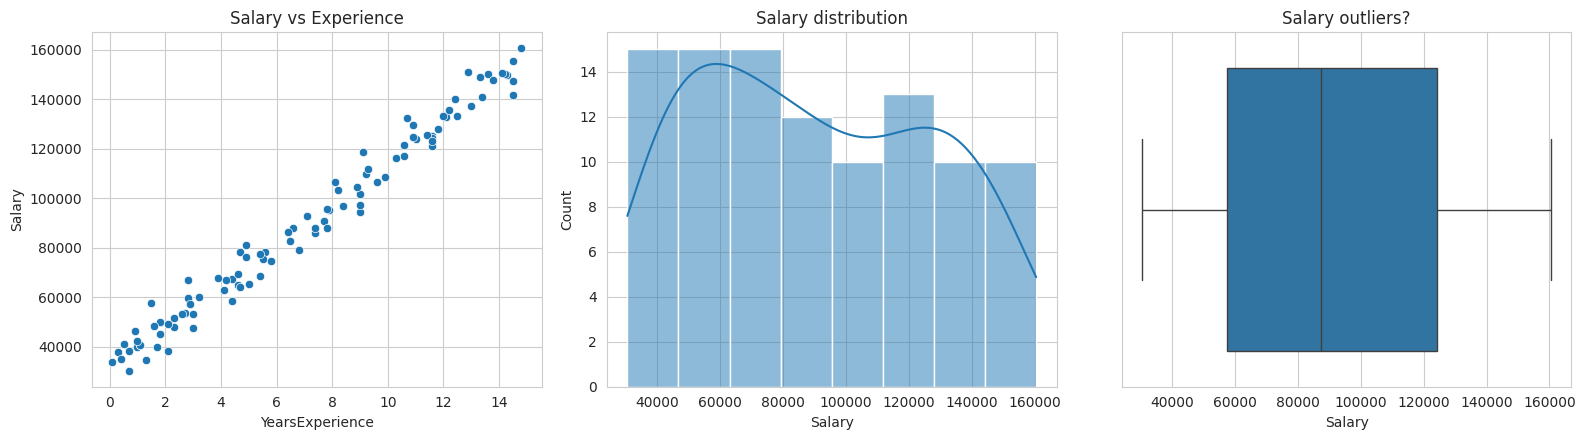

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.scatterplot(data=df, x="YearsExperience", y="Salary", ax=axes[0]); axes[0].set_title("Salary vs Experience")
sns.histplot(df["Salary"], kde=True, ax=axes[1]); axes[1].set_title("Salary distribution")
sns.boxplot(x=df["Salary"], ax=axes[2]); axes[2].set_title("Salary outliers?")
plt.tight_layout(); plt.show()

## Step 5: Model Training
Three ways, one answer: **(a)** normal equation, **(b)** gradient descent, **(c)** scikit-learn.

(a) Normal equation : intercept = 30863.46, slope = 8338.61
(b) Gradient descent: intercept = 30863.46, slope = 8338.61


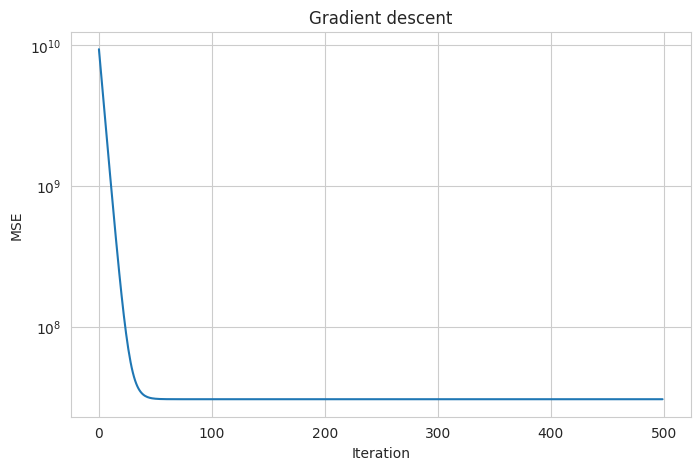

(c) scikit-learn    : intercept = 30863.46, slope = 8338.61


In [7]:
# (a) Normal equation
Xb = np.c_[np.ones(len(X_train)), X_train.values]
theta = np.linalg.inv(Xb.T @ Xb) @ Xb.T @ y_train.values
print(f"(a) Normal equation : intercept = {theta[0]:.2f}, slope = {theta[1]:.2f}")

# (b) Gradient descent (on scaled x for stable convergence)
x = X_train.values.ravel(); mu, sd = x.mean(), x.std()
xs = (x - mu) / sd
w, b, lr, losses = 0.0, 0.0, 0.1, []
for _ in range(500):
    err = (w * xs + b) - y_train.values
    w -= lr * np.mean(err * xs); b -= lr * np.mean(err)
    losses.append(np.mean(err ** 2))
slope_gd = w / sd; intercept_gd = b - w * mu / sd
print(f"(b) Gradient descent: intercept = {intercept_gd:.2f}, slope = {slope_gd:.2f}")
plt.plot(losses); plt.xlabel("Iteration"); plt.ylabel("MSE"); plt.title("Gradient descent"); plt.yscale("log"); plt.show()

# (c) scikit-learn
from sklearn.linear_model import LinearRegression
model = LinearRegression().fit(X_train, y_train)
print(f"(c) scikit-learn    : intercept = {model.intercept_:.2f}, slope = {model.coef_[0]:.2f}")

## Step 6: Model Evaluation
Metrics on both train and test data, the fitted line, and **residual analysis** to check the regression assumptions.

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def report(name, y_true, y_hat):
    mse = mean_squared_error(y_true, y_hat)
    print(f"{name:<6} MAE={mean_absolute_error(y_true, y_hat):>9.2f}  MSE={mse:>14.2f}  RMSE={np.sqrt(mse):>9.2f}  R2={r2_score(y_true, y_hat):.4f}")

y_pred_train, y_pred = model.predict(X_train), model.predict(X_test)
report("Train", y_train, y_pred_train)
report("Test", y_test, y_pred)

Train  MAE=  4407.45  MSE=   30512915.32  RMSE=  5523.85  R2=0.9775
Test   MAE=  3546.35  MSE=   23519193.96  RMSE=  4849.66  R2=0.9845


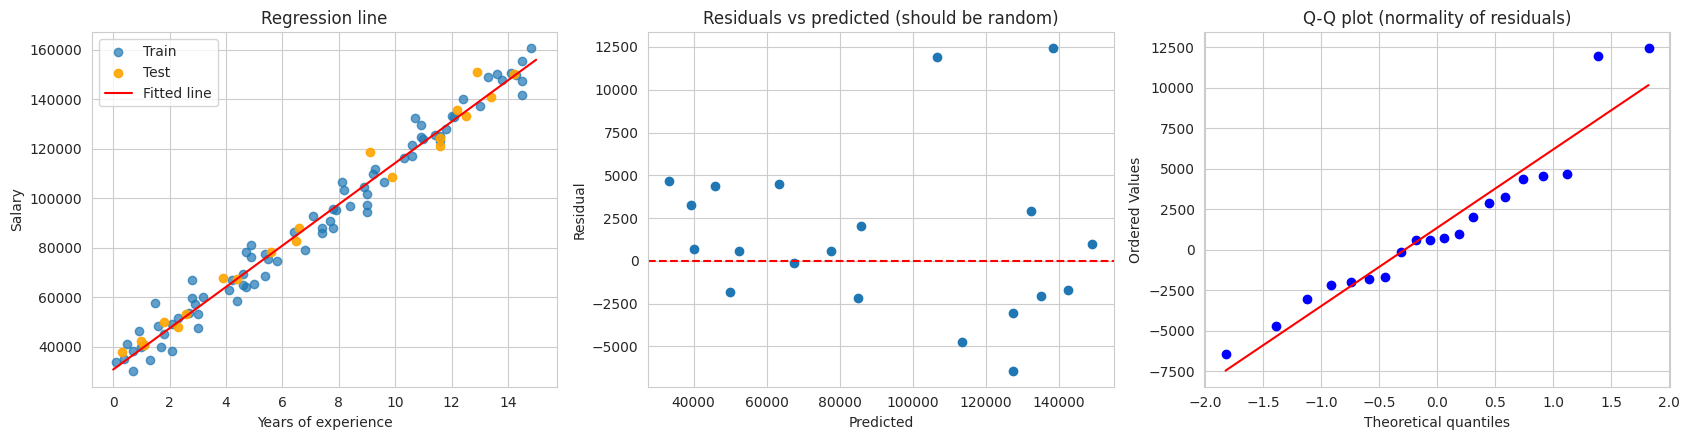

In [9]:
from scipy import stats

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(X_train, y_train, label="Train", alpha=.7); axes[0].scatter(X_test, y_test, label="Test", alpha=.9, color="orange")
grid = np.linspace(0, 15, 100).reshape(-1, 1)
axes[0].plot(grid, model.predict(grid), color="red", label="Fitted line")
axes[0].set_xlabel("Years of experience"); axes[0].set_ylabel("Salary"); axes[0].legend(); axes[0].set_title("Regression line")

residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals); axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Residual"); axes[1].set_title("Residuals vs predicted (should be random)")
stats.probplot(residuals, dist="norm", plot=axes[2]); axes[2].set_title("Q-Q plot (normality of residuals)")
plt.tight_layout(); plt.show()

## Step 7: Prediction on New Data

In [10]:
for yrs in [1.5, 5, 10, 14]:
    print(f"Experience = {yrs:>4} years -> predicted salary = {model.predict(pd.DataFrame({'YearsExperience': [yrs]}))[0]:,.0f}")

Experience =  1.5 years -> predicted salary = 43,371
Experience =    5 years -> predicted salary = 72,556
Experience =   10 years -> predicted salary = 114,250
Experience =   14 years -> predicted salary = 147,604


## Conclusion
All three methods recovered a slope of roughly 8,300-8,500 salary units per year of experience and an intercept near 30,000-31,000, close to the values used to generate the data (8,500 and 30,000). The test R-squared is above 0.95 and the residuals look random and roughly normal, so the linear-model assumptions hold. Predictions outside the observed range (0-15 years) should not be trusted (extrapolation).